# REPORT ON GENETIC ALGORITHMS

### Data preparation for testing
To properly test our implementation we need larger files for comprehensive evaluation. For that we need to categorize our test files.

1. **Categorization**
    1. large vs small inputs
    2. easy vs hard inputs
    3. impossible inputs

By using these categories we create solvable:
- SmallEasy, SmallHard, LargeEasy, LargeHard.

and unsolvable:
-  ImpossibleRoom, ImpossibleTeacher

2. **Aproach used**

To generate test data we first prepared a valid schedule and then generated the files from it. Using this approach we know if the GA fails it is GA's fault and not hours.

In [329]:
import random,  heapq, os

In [330]:
# we need to create rooms, assign the lectures and assign Teachers

SCHOOL_START = 7
SCHOOL_END = 20
SCHOOL_START_TEACHERS = 9
SCHOOL_END_TEACHERS = 16

def make_classrooms(n_classes, rng):
    classrooms = []
    for i in range(n_classes):
        classroomOpen = rng.randint(6, 10) # how many hours classroom is open
        openingTime = rng.randint(SCHOOL_START, SCHOOL_END - classroomOpen) # time the classroom opens
        classrooms.append((f"P{i + 1}", openingTime, openingTime + classroomOpen))
    
    return classrooms


In [331]:
# add lectures to the classroms

def assing_classes(classrooms, used, rng) :
    classes = []
    for i, (roomName, open, close) in enumerate(classrooms):
        availableTime = round((close - open) * used) # how many hours available
        startTime = open
        while availableTime > 0: 
            classDuration = min(rng.choice([1,2,2,3,3]), availableTime, close - startTime) # with this we get max usage -> we prioritize 2 and 3 when posible
            if classDuration <= 0:  #move into next classrom
                break
            classes.append((classDuration, i, startTime)) # (duration, classromIndex, startTime)
            startTime += classDuration
            availableTime -= classDuration
    return classes

In [332]:
# here we dont care what they teach, just when they have time
# what they teach assigned latter
# 2. Possible option
#   1. 1 teacher per classroom -> simple but not realistic
#   2. we make greedy algo for seleting the one who has been free longest more realistic
# (duration, classroom, start, teacher)
def assign_teachers(classes, n_teachers) : 
    heap = [(0, t) for t in range(n_teachers)] #all free
    heapq.heapify(heap)

    #we need to order classes by startime
    classes.sort(key=lambda c: c[2]) # sort th lectures by startime

    teaches = []
    for duration, classroom, start in classes :
        teachesUntil, teacher = heapq.heappop(heap)
        if teachesUntil > start:
            raise ValueError("not enough teachers")
        teaches.append((duration, classroom, start, teacher))
        heapq.heappush(heap, (start + duration, teacher))
    return teaches

    

In [333]:
def build_test_data(n_classrooms, used, n_teachers, rng, max_lectures_per_class, exstraTeachers ) :
    #Create a working example
    classrooms =  make_classrooms(n_classrooms, rng)
    classes = assing_classes(classrooms, used, rng) # (duration, id, startTime)   
    teachers = assign_teachers(classes, n_teachers) # (duration, classroom, start, teacher)
    #We shuffle since we put them in correct order
    rng.shuffle(teachers)

    # Now we need to group the claases together and assign them names
    # Then assign which teacher teaches what

    #First we group the lectures 
    groupedClasses = [] # (duration, classroom, start, teacher)
    i = 0
    while i < len(teachers) : 
        lecturesPerClass = rng.randint(2, max_lectures_per_class) # how many lectures a class has
        groupedClasses.append(teachers[i:i + lecturesPerClass]) # because of this its important its shuffled otherwise they are consecutive classes
        i += lecturesPerClass

    canTeach = {teacher: set() for teacher in range(n_teachers)} # dict. (id: set(), )

    for c, lectures in enumerate(groupedClasses) :
        #in hard only 1 teacher
        for duration, classroom, start, teacher in lectures:
            canTeach[teacher].add(c)
        # For easy example we need  more teacher to teach sam subject
        for t in  rng.sample(range(n_teachers), exstraTeachers) :
            canTeach[t].add(c)

    # give classes names
    classNames = []
    for c in range(len(groupedClasses)):
        classNames.append(f"C{c + 1}")

    # We get C1 [1, 2, 2, ...]
    classesOut = []
    for c, lectures in enumerate(groupedClasses):
        durations = []
        for duration, classroom, start, teacher in lectures:
            durations.append(duration)
        classesOut.append((classNames[c], durations))

    # We get T1 [C1 C2 ...]
    teachersOut = []
    for t in range(n_teachers):
        names = []
        for c in sorted(canTeach[t]):
            names.append(classNames[c])
        teachersOut.append((f"T{t + 1}", names))

    # Prepaed solution
    prepared = []
    for c, lectures in enumerate(groupedClasses):
        for duration, room, start, teacher in lectures:
            prepared.append((classNames[c], duration, classrooms[room][0], start, f"T{teacher + 1}"))

    return classrooms, classesOut, teachersOut, prepared
    

In [334]:
# lets make some assumptions
# They dont want to teach in the morning
# also not in the evening so lets say 9-17 would be ideal for them
# For dislikes its also possible they dont like 
def make_teachers_preferences(teachersOut, rng) :
    inputs = []
    for name, className in teachersOut:
        likesToStart = rng.randint(SCHOOL_START_TEACHERS, SCHOOL_END_TEACHERS)
        likesToWork = [likesToStart, likesToStart + rng.randint(2,4)]

        # we are trying until likes and dislikes are not covering
        while True:
            dislikesToStart = rng.randint(SCHOOL_START, SCHOOL_END - 2) # -2 so we inside workday
            dislikesToWork = [dislikesToStart, dislikesToStart + rng.randint(1,2)]

            if dislikesToWork[1] <= likesToWork[0] or dislikesToWork[0] >= likesToWork[1]:
                break

        inputs.append(f'{name} {{"likes": {likesToWork}, "dislikes": {dislikesToWork}}}')
    return inputs



In [335]:
def write_files(folder, classrooms, classesOut, teachersOut, prepared, rng):
    os.makedirs(folder, exist_ok=True)

    #Creates claases
    inputs = []
    for name, durations in classesOut : 
        durationsText = ", ".join(str(d) for d in durations)
        inputs.append(f"{name} [{durationsText}]")
    with open(os.path.join(folder, "Classes.txt"), "w", encoding="utf-8") as file:
        file.write("\n".join(inputs))

    #Classrooms.txt
    inputs = []
    for name, opens, closes in classrooms:
        inputs.append(f"{name} [{opens}, {closes}]")
    with open(os.path.join(folder, "Classrooms.txt"), "w", encoding="utf-8") as file:
        file.write("\n".join(inputs))

    #Teachers.txt
    inputs = []
    for name, classNames in teachersOut:
        inputs.append(f"{name} [{', '.join(classNames)}]")
    with open(os.path.join(folder, "Teachers.txt"), "w", encoding="utf-8") as file:
        file.write("\n".join(inputs))

    #Solution
    inputs = []
    for className, duration, classroom, start, teacher in prepared:
        inputs.append(f"{className} {duration} {classroom} {start} {teacher}")
    with open(os.path.join(folder, "prepared_solution.txt"), "w", encoding="utf-8") as file:
        file.write("\n".join(inputs))

    #Preferences
    with open(os.path.join(folder, "Preferences.txt"), "w", encoding="utf-8") as file:
        file.write("\n".join(make_teachers_preferences(teachersOut, rng)))
        

In [336]:

# Name : (n_classrooms, used, n_teachers, n_classes, n_exstra_teacers)
# at hard no exstra teacher only 2 per subject
CATEGORIZATION  = {
"SmallEasy": (7,    0.40,   7,  3,  2),
"SmallHard": (3,    0.90,   3,  3,  0),
"LargeEasy": (18,   0.40,   18, 4,  3),
"LargeHard": (8,    0.90,   8,  4,  0),
}

rng = random.Random(2026)   # one seed for all sets -> same files every run

for name, (n_classrooms, used, n_teachers, max_lectures, n_extra) in CATEGORIZATION.items():
    classrooms, classesOut, teachersOut, prepared = build_test_data(n_classrooms, used, n_teachers, rng, max_lectures, n_extra)
    
    write_files(os.path.join("Data4", name), classrooms, classesOut, teachersOut, prepared, rng)
    
    print(f"{name}: {len(classesOut)} classes, {len(prepared)} lectures, "f"{n_classrooms} rooms, {n_teachers} teachers")

SmallEasy: 5 classes, 14 lectures, 7 rooms, 7 teachers
SmallHard: 4 classes, 10 lectures, 3 rooms, 3 teachers
LargeEasy: 11 classes, 32 lectures, 18 rooms, 18 teachers
LargeHard: 9 classes, 25 lectures, 8 rooms, 8 teachers


### Common setup

This functions are the same for task 1-3, so they will be reused. They cover how we load and globaly store data and our timing functions. Also the schedule and time print functions belong here.

In [337]:
import numpy as np
import pygad
import matplotlib.pyplot as plt
import pandas as pd
import json

In [338]:
# reads formats Name [1, 2, 3] -> returns dictionary {"Name": ["1", "2", "3"]}
def read_txt_to_dict(path):
    # dictionary
    slovar = dict()
    # Open the file
    with open(path, 'r') as file:
        
        for line in file:
            # Cleaning the line
            splited = line.replace(",", "").replace("[", "").replace("]", "").replace("\n", "").split()
            # Filling dictionary
            slovar[splited[0]] = splited[1:]
  
    return slovar

classes = read_txt_to_dict("Data\\Classes.txt")
classrooms = read_txt_to_dict("Data\\Classrooms.txt")
teachers = read_txt_to_dict("Data\\Teachers.txt")

# reads format "Name {json}" -> return {"Name": {"likes": [..], "dislikes": [..]}}
def load_preferences(folder):
    preferences = dict()
    with open(f"{folder}\\Preferences.txt", 'r', encoding="utf-8") as file:
        for line in file:
            # Splits only by first space
            name, string = line.split(" ", 1)
            string = string.replace("“", '"').replace("”", '"')
            preferences[name] = json.loads(string)
    return preferences

preferences = load_preferences("Data")
print("preferences:", preferences)
  

preferences: {'Anna': {'likes': [10, 11], 'dislikes': [12, 14]}, 'Brian': {'likes': [10, 14], 'dislikes': [15, 16]}, 'Charles': {'likes': [10, 11], 'dislikes': [12, 16]}, 'Diana': {'likes': [10, 14], 'dislikes': [15, 16]}}


In [339]:
# Index xy -> x: 0:Programming, 1:Math, 2:Algorithms, 3:OperatingSystems
#          -> y: Which lecture is used

# Loads one data folder and builds the lookup tables used by the GA.
# Every lecture is assigned an ID (0,1,2, ...) and is mapped back to class with lectureClass 
def load_data(folder):

    classes = read_txt_to_dict(f"{folder}\\Classes.txt")
    classrooms = read_txt_to_dict(f"{folder}\\Classrooms.txt")
    teachers = read_txt_to_dict(f"{folder}\\Teachers.txt")

    idClasses = []
    globalIdClassDictionary = {}
    slovarTrajanjaUr = {}
    lectureClass = {} # lecture id -> class index
    idLecture = 0
    indexClass = {}

    for id, nameClass in enumerate(classes):
        for duration in classes[nameClass]: 
            idClasses.append(idLecture)
            slovarTrajanjaUr[idLecture] = int(duration)
            lectureClass[idLecture] = id
            # Class name - hourTime - id
            globalIdClassDictionary[idLecture] = f"{nameClass}-{idLecture} ({duration})"
            idLecture+=1

        # added class index
        indexClass[nameClass] = id

    #print("indexClass:", indexClass)

    # Classroom Index: 0:P1, 1:P2, 2:P3, 3:P4
    # classroomTime: on index x is start_time and end_time
    idClassroom = []
    classroomTime = []
    globalIdClassroomsDictionary = {}

    for id, clas in enumerate(classrooms):

        c = classrooms[clas]
        classroomTime.append([int(c[0]), int(c[1])])

        globalIdClassroomsDictionary[id] = f"{clas} ({c[0]}-{c[1]})"

        idClassroom.append(id)

    # Teachers assigned own index
    # TeachdrClass[] = list classes they can teach by index
    # for task 4 generalized to use indexClasses to look up classes -> unlimited teachers/classes
    idTeacher = []
    teacherClass = []
    globalIdTeachersDictionary = {}

    for id, t in enumerate(teachers):
        idTeacher.append(id)

        globalIdTeachersDictionary[id] = t

        # Which lectures indexed for teachers
        h = []
        for lecture in teachers[t]:
            # Index of a class
            h.append(indexClass[lecture])

        teacherClass.append(h)

    return (idClasses, slovarTrajanjaUr, lectureClass, globalIdClassDictionary,
            idClassroom, classroomTime, globalIdClassroomsDictionary,
            idTeacher, teacherClass, globalIdTeachersDictionary)


(idClasses, slovarTrajanjaUr, lectureClass, globalIdClassDictionary,
idClassroom, classroomTime, globalIdClassroomsDictionary,
idTeacher, teacherClass, globalIdTeachersDictionary) = load_data("Data")


print("idClasses:", idClasses, " -  SlovarTrajanjaUr:", slovarTrajanjaUr, "- lectureClass:", lectureClass)
print("idClassroom:", idClassroom, " -  classroomTime" ,classroomTime)
print("idTeacher:", idTeacher, " -  teacherClass:", teacherClass,"\n")

print("globalIdClassDictionary", globalIdClassDictionary)
print("globalIdClassroomsDictionary", globalIdClassroomsDictionary)
print("globalIdTeachersDictionary", globalIdTeachersDictionary)

idClasses: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]  -  SlovarTrajanjaUr: {0: 2, 1: 3, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 3, 8: 2, 9: 2} - lectureClass: {0: 0, 1: 0, 2: 0, 3: 0, 4: 1, 5: 1, 6: 2, 7: 2, 8: 3, 9: 3}
idClassroom: [0, 1, 2, 3]  -  classroomTime [[10, 16], [8, 16], [10, 16], [10, 16]]
idTeacher: [0, 1, 2, 3]  -  teacherClass: [[0, 1], [0, 2, 3], [1], [2, 3]] 

globalIdClassDictionary {0: 'Programming-0 (2)', 1: 'Programming-1 (3)', 2: 'Programming-2 (2)', 3: 'Programming-3 (2)', 4: 'Math-4 (2)', 5: 'Math-5 (2)', 6: 'Algorithms-6 (2)', 7: 'Algorithms-7 (3)', 8: 'OperatingSystems-8 (2)', 9: 'OperatingSystems-9 (2)'}
globalIdClassroomsDictionary {0: 'P1 (10-16)', 1: 'P2 (8-16)', 2: 'P3 (10-16)', 3: 'P4 (10-16)'}
globalIdTeachersDictionary {0: 'Anna', 1: 'Brian', 2: 'Charles', 3: 'Diana'}


In [340]:
def display_schedule(schedule):

    # Group lectures by classroom ID
    classrooms = {}
    for lec in schedule:      
        idClass, idClassroom, startHour, idTeacher = lec
        # You cannot index by float round number
        idClass, idClassroom, startHour, idTeacher = int(idClass), int(idClassroom), int(startHour), int(idTeacher)
        # Saving all hours to a specific classroom - here we didn't yet found it
        if idClassroom not in classrooms:
            classrooms[idClassroom] = []

        classrooms[idClassroom].append((startHour, idClass, idTeacher))

    # Sort classrooms by ID for output
    for idClassroom in sorted(classrooms.keys()):
        classroomName = globalIdClassroomsDictionary[idClassroom]       
        print(f"\n{classroomName}")
        print("-" * 40)
        
        # Sort lectures in this classroom by start hour
        lectures = sorted(classrooms[idClassroom], key=lambda x: x[0])
        
        for start_hour, id_class, id_teacher in lectures:            
            classsName = globalIdClassDictionary[id_class]
            teachername = globalIdTeachersDictionary[id_teacher]
            endHour = start_hour + slovarTrajanjaUr[id_class]
            print(f"  [ {start_hour:02d}:00 - {endHour:02d}:00 ] -> {classsName} (Taught by: {teachername})")
    

In [341]:
# We need a function to loop the folders and save variables globaly
def set_data(folder):
    global idClasses, slovarTrajanjaUr, lectureClass, globalIdClassDictionary
    global idClassroom, classroomTime, globalIdClassroomsDictionary
    global idTeacher, teacherClass, globalIdTeachersDictionary
    (idClasses, slovarTrajanjaUr, lectureClass, globalIdClassDictionary,
     idClassroom, classroomTime, globalIdClassroomsDictionary,
     idTeacher, teacherClass, globalIdTeachersDictionary) = load_data(folder)

In [342]:
def printTimes(result):

    allTime = 0
    for name, value in result["times"].items():
        if name != "latest_call_back":
            avg = value / len(result["fitnessScores"])   # generations that actually ran
            allTime += value
            print(f"{name}: {value:.4f} s -> avg per step: {avg*1000:.4f} ms")

    plt.plot(np.arange(0, len(result["fitnessScores"])), result["fitnessScores"])
    plt.title("Fitness score for each generation")
    plt.show()

### Timing and fitnes tracking

For this we use PyGAD callbacks to measure how long each step of the GA took.
For each callback we are adding the time from the previous callback to its bucket.

Buckets:
1. Overhead     -> time beetween the generations
2. parents      -> measures parent selection
3. mutatioon    -> measures mutation
3. fitnes       -> its the fitnes of new population (its computeted at the end of generation)

on_start -> resets everythign so same callbacks can be reused
fitnessScores -> store the best fitnes of each generation

In [343]:
# From https://pygad.readthedocs.io/en/latest/custom_functions.html
import time

# How quickly does the fitness score increase
fitnessScores = []

# in every call back this will sub to get the time for that callback, 
# and than updated by current time in callback
# Adding time to a dictionary
timeDictionary = {
    "overhead": 0, "parents": 0, "crossover": 0, "mutation": 0, "fitness": 0,
    "latest_call_back": 0
}

# When GA starts
def on_start(ga_instance):
    fitnessScores.clear()
    for key in timeDictionary:
        timeDictionary[key] = 0
    # Setting the time when GA starts
    timeDictionary["latest_call_back"] = time.perf_counter()

# When fitness score is calculated
def on_fitness(ga_instance, last_gen_fitness):

    call_back = time.perf_counter()
    # call_back - latest_call_back = time that it took to complete this step!
    # We sum together ans average in the end
    timeDictionary["overhead"] += call_back - timeDictionary["latest_call_back"]
    # Save last callback
    timeDictionary["latest_call_back"] = call_back

# After parents selection
def on_parents(ga_instance, last_gen_parents):
    
    call_back = time.perf_counter()
    timeDictionary["parents"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# After crossover is finished
def on_crossover(ga_instance, last_gen_offspring):
    
    call_back = time.perf_counter()
    timeDictionary["crossover"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# After mutation
def on_mutation(ga_instance, last_gen_offspring):
        
    call_back = time.perf_counter()
    timeDictionary["mutation"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# At the end of the generation
def on_generation(ga_instance):

    call_back = time.perf_counter()
    timeDictionary["fitness"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

    # gives max fitness 
    fitnessScores.append(np.max(ga_instance.last_generation_fitness, axis=0))

### TASK 1 : BASIC GA

The goal of task 1 was to build a valid schedule using GA.

**Data representation**

A schedule is a flat chromosome with 4 genes per lecture:
`[id_Class, id_Classroom, startHour, id_Teacher, id_Class, id_Classroom, ...]`
The genes can only be picked from the gene space: existing (classes, classrooms, opening hours, teachers).

**Fitnes function**

Our fitness function sums penatilties when the rules are broken because GA maximazies we used -f. So valid scores is =0.

**Rules and penalties:**

The weight were set by hand, depending how much they were affecting our fitness score.

1. lecture missing or duplicated → **10**
2. teacher teaching wrong lecture→ **10**
3. lecture outside schedules hours → **6** per hour
4. two lectures in the same classroom at once → **3** per extra lecture per hour
5. teacher teaches two lectures at once → **3** per hour

**Reasoning for rules**

1, 2 -> schedule is unusable:
For lectures missing, duplicated or when professor was teaching the wrong lecture we decided on 10, because when one lecture duplicated another one is missing. Also when looking at it from a practical point this makes schedule completely unusable.

3 -> 6 Per hour:
The lecture still takes place, people just have to come earlier or stay later.
Penaties are applied per hour not per lecture. Meaning if they are 3 hours to early/late the punisment increases. This help GA see improvement if it selects the correct direction.

4, 5 -> 3 per hour
The teacher overlap is a flap 3. But for classrooms we decided to punish them more, since you would run out of space, teacher can always move. So the punshisments grow per number of
lectures overlaping(2 at once -> 3, 3 -> 6, ...)


In [344]:
# suitable fitness function that will reward schedules that satisfy the conditions and penalize those that do not.
def f(schedule):
    # (idClass, idClassroom, start, idteacher)

    # Global count fitness score
    issue = 0
    # • Every lecture in the classes file must be present in the schedule
    for cid in idClasses:
        find = 0    
        
        # Find if exists 
        for lecture in schedule:
            if lecture[0] == cid: 
                find += 1
            
        # If one lecture/class is not found penatly is high
        if find == 0: 
            issue += 10

        # If some duplicates
        if find > 1:
            issue += 10


    # Every lecture needs to be assigned to a classroom at a time when that classroom is available. 
    # Array is build 0 - unocupied , 1 - occupied and >1 means more lectures same time
    spots = [ [ 0 for j in range(razred[1]-razred[0])] for razred in classroomTime]
    
    # Teachers hours (end before hour 20) -> changed to 24 ask patrik?
    teacherSpots = [ [0 for j in range(24)] for _ in idTeacher]

    for lec in schedule:
                
        id_Class, id_Classroom, startHour, id_Teacher = lec
        # You cannot index by float round number
        id_Class, id_Classroom, startHour, id_Teacher = int(id_Class), int(id_Classroom), int(startHour), int(id_Teacher)
    
        # From slovar of hours i get when does this class end 
        endHour = startHour + slovarTrajanjaUr[id_Class]
    
        # What index should it fill (Normalizing so it starts with 0 - for array)
        startIndToFill = startHour - classroomTime[id_Classroom][0]
        endIndToFill = endHour - classroomTime[id_Classroom][0]

        # For how many hours the classroom is open
        dolg = classroomTime[id_Classroom][1] - classroomTime[id_Classroom][0]

        # if the class starts before the classroom opens - penatly (that many hours that is late - increment issue)
        if startHour < classroomTime[id_Classroom][0]:       
            issue += abs(classroomTime[id_Classroom][0] - startHour) * 6
            # The lecture will not be added so +10, because it goes before time 
            
        # if class goes longer than the classroom is opne (14-17)=14,15,16 -> thats why -1       
        if endHour > classroomTime[id_Classroom][1]:
            issue += (endHour - classroomTime[id_Classroom][1]) * 6
                
        validStart = max(startIndToFill, 0)
        validEnd = min(endIndToFill, dolg)
       
        for i in range(validStart, validEnd):
            spots[id_Classroom][i]+=1

            # Lectures cannot overlap in the same classroom: a single classroom can hold only a single lecture in a given hour.
            # For every value that is more than 1 -> +1 issue
            if spots[id_Classroom][i] > 1: issue += 3 * (spots[id_Classroom][i] - 1)

        # Teachers cannot teach more than one lecture at the same time.
        for i in range(startHour, min(endHour, 24)):
            
            # If teacher already has a class at that hour
            if teacherSpots[id_Teacher][i] > 0:
                issue += 3
            teacherSpots[id_Teacher][i] += 1

        # Every lecture needs to be assigned a teacher (That teaches that class) 
        # Which classes can the teacher teach
        canTeach = teacherClass[id_Teacher]
        teachingClass = lectureClass[id_Class]

        if teachingClass not in canTeach:
            issue+=10
       
    return issue

# Negating the value to minimize the fitness_score (in this case error rate)
def fitness_function(ga_instance, solution, x_idx):

    # solution is flat so I had to make it 2D
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]

    return -f(schedule)

In [345]:
def run_task1(folder, seed, num_generations=200, sol_per_pop=50, num_parents_mating=10,
              crossover_type="uniform", mutation_type="swap"):
    set_data(folder)

    # same gene space as Task 1
    earliest = min(t[0] for t in classroomTime)
    latest = max(t[1] for t in classroomTime)
    startHours = list(range(earliest, latest))
    
    gene_space = []
    for _ in range(len(idClasses)):
        gene_space.extend([
            idClasses,
            idClassroom,
            startHours,
            idTeacher])

    ga_instance = pygad.GA(
        fitness_func=fitness_function,
        num_generations=num_generations,
        num_parents_mating=num_parents_mating,
        sol_per_pop=sol_per_pop,
        num_genes=len(gene_space),
        gene_space=gene_space,
        crossover_type=crossover_type,
        mutation_type=mutation_type,
        allow_duplicate_genes=True,
        random_seed=seed,
        on_start=on_start, on_fitness=on_fitness, on_parents=on_parents,
        on_crossover=on_crossover, on_mutation=on_mutation, on_generation=on_generation)

    start = time.perf_counter()
    ga_instance.run()
    totalTime = time.perf_counter() - start

    solution, bestFitness, _ = ga_instance.best_solution()
    return {
        "fitness": bestFitness,
        "time": totalTime,
        "fitnessScores": list(fitnessScores),   # copy -> on_start clears the global list
        "times": dict(timeDictionary),          # copy, same reason
        "solution": solution,
    }

    

### Task 1 : swap vs random mutation

In task 1 we used swap. Now we are going to compare it other options we were discusing which is random. Both of them will be ran on all 4 different dataset.

They will be evaluated based on : 
- fitness score
- succes rate -> how many reach 0
- time 
- time per step


In [346]:
DATA_SETS = ["Data4/SmallEasy", "Data4/SmallHard", "Data4/LargeEasy", "Data4/LargeHard"]
SEEDS = range(5)          # on how many seeds we run
MUTATIONS = ["swap", "random"]

In [ ]:
results = []
for data in DATA_SETS:
    for mutation in MUTATIONS :
        for seed in SEEDS:
            # ("fitness", "time", "fitnessScores", "times", "solution")
            ga_results = run_task1(data, seed, mutation_type=mutation) 
            results.append({
                "data_set": data,
                "mutation": mutation,
                "seed": seed,
                "fitness": ga_results["fitness"],
                "time": ga_results["time"],
                "fitnessScores": ga_results["fitnessScores"]
            })
            # Print is to unredable for final report
            #print(data, "| Mutation: ", mutation , "| Seed: ", seed, "| Fitness: ",ga_results["fitness"], "| Time: ", f"{ga_results['time']:.1f} s")

# Better than print, still to much data
# lets sum the data and present best values and avergaes
results_task1 = pd.DataFrame(results)
# results_task1

In [ ]:
summary = results_task1.groupby(["data_set", "mutation"]).agg(
    expected=("fitness", lambda x: 0),
    best=("fitness", "max"),
    mean=("fitness", "mean"),
    valid=("fitness", lambda x: f"{(x == 0).sum()}/{len(x)}"),
    time_s=("time", "mean"),
).round(2)

summary

expected  best   mean valid  time_s
data_set        mutation                                     
Data4/LargeEasy random           0  -189 -214.0   0/5    3.82
                swap             0   -50  -64.0   0/5   27.52
Data4/LargeHard random           0  -182 -208.2   0/5    2.94
                swap             0   -40  -52.8   0/5   16.66
Data4/SmallEasy random           0    -3   -9.8   0/5    1.35
                swap             0     0  -12.0   2/5    7.90
Data4/SmallHard random           0   -15  -18.0   0/5    1.12
                swap             0    -3  -21.0   0/5    4.81

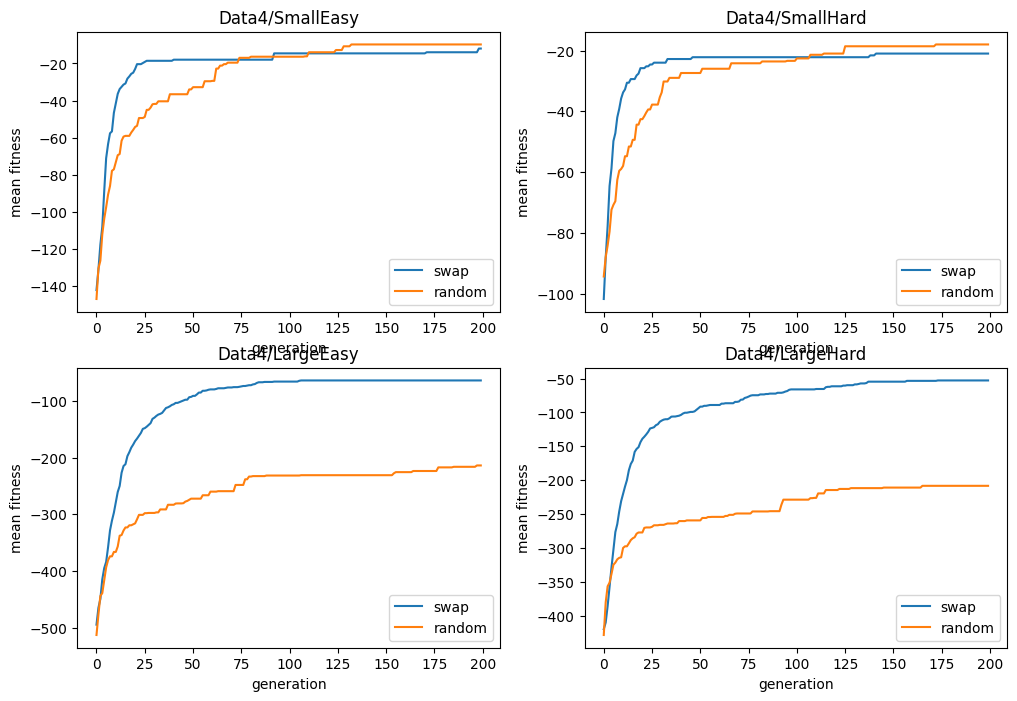

In [ ]:
#We will plot this onto 4 graps 1 for each data_set
meanLines = results_task1.groupby(["data_set", "mutation"])["fitnessScores"].apply(lambda c: np.mean(c.tolist(), axis=0))

plt.figure(figsize=(12, 8))
for i, folder in enumerate(DATA_SETS) : 
    plt.subplot(2, 2, i + 1) # 2x2
    for mutation in MUTATIONS :
        plt.plot(meanLines[(folder, mutation)], label=mutation)
    plt.title(folder)
    plt.xlabel("generation")
    plt.ylabel("mean fitness")
    plt.legend()
plt.show()


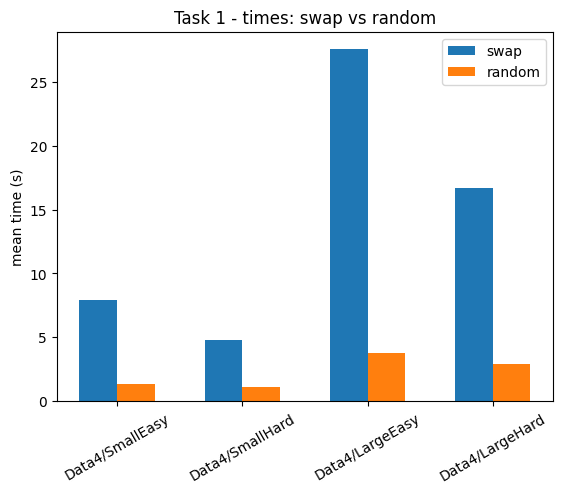

In [ ]:
x = np.arange(len(DATA_SETS))
width = 0.3

for i, mutation in enumerate(MUTATIONS):
    avg_times = [summary.loc[(folder, mutation), "time_s"] for folder in DATA_SETS]
    plt.bar(x + i * width, avg_times, width, label=mutation)

plt.xticks(x + width / 2, DATA_SETS, rotation = 30)
plt.ylabel("mean time (s)")
plt.title("Task 1 - times: swap vs random")
plt.legend()
plt.show()

## Task 1 : Evaluation swap vs random

### Fitness evaluation findings

1. **Swap improves faster on all 4 datasets**
We can see the slope increase the most in the first 25 generations. Swap more consistently since it only tries the values already in the schedule so the changes are small, but at time cost.

2. **Similar on small datasets - difficulty does not matter**
We can see random catch up to swap between 80-100 generations. This is because on smaller data sets both can reach all conbinations pretty quicly and come to similar conclusion.

3. **Large sets**
For the large data sets the swap performs better since it only switches the 2 values that are already in the schedule. The changes are small but consinsent. On the other hand random swaps 10% of the genes, whic also creates a lot of duplicates and missing lectures.


IMPORTANT : **Both get stuck** -> meaning none reach 0, they do work since we see improvement in fitness, but they do not reach 0. We saw it working on small imputs but when it comes to scalling they fail.

## Time evaluation ##

The gap between the swap and random grows with data size. Most of the time at swap goes into mutation also covered in task 1. The reason is when swaping pairs they break gene space and then GA keeps retrying tillit succeds.


## TASK 2 : Custom population, crossover and mutation

In Task 2 we replace PyGAD built-in functions, with custom ones we created with the knowledge of the proble. The fitness function and the punisments same as Task 1.

**Initial population**

In the population every lecture appears only once and we place them into the classrooms back to back within the opening hour and each is assigned a teacher who can teach it.

**Crossover funtion**

We decided on the single point crossover over double point crossover. So we cut only beetween every 4 genes so we leave the lectures whole. In the beggining we also sort the lectures, so we are not getting duplicates or missing lectures as a result of crossover.

**Mutation**

With mutation we are changing one gene of the child, but never the lecture ID.
1. Classroom: We switch classrom if the lecture fits into the opening hours of the new classroom
2. Start hour : gets randomly added +1 or -1, but only if it stays inside opening hours
3. teacher: lecture get assigned a new teacher if he is capable of teaching, otherwise does not switch

**Evaluation**

Here we will add:
- generations to solution -> how many generations are needed for fitness to reach 0

In [ ]:
import random

# Generating your own initial population. (so generating some valid schedule (or almost valid))
# Better than the GA generated
# I will build valid for first 2 constraint (for teachers it gets more complicated) -> but for teacher who can teach only x class WILL DO
def initialPopulationFunc():

    arrayClasses = np.copy(idClasses)
    schedule = []
    # startHour: When does class starts, classroomIndex -> which classroom are we in now
    start_Hour = classroomTime[0][0]
    classroomIndex = 0

    # To know how much did we already add lectures
    offsetStartClassroom = [0 for i in range(len(idClassroom))]

    for _ in arrayClasses:
        id_Class = random.choice(arrayClasses)
        arrayClasses = arrayClasses[arrayClasses != id_Class]

        triedClassrooms  = 0
        possible = True

        # Get avaible classroom (when can it start) (should all fit -> loop continuesly)
        while start_Hour + slovarTrajanjaUr[id_Class] > classroomTime[classroomIndex][1]:

            # tried all classrooms -> cant fit
            if triedClassrooms  == len(idClassroom):
                possible = False
                break

            # To not over indexed (so in a loop)
            classroomIndex += 1 
            classroomIndex %= len(idClassroom)
            # When the classroom is still free (from what time)
            start_Hour = classroomTime[classroomIndex][0] + offsetStartClassroom[classroomIndex]
            triedClassrooms += 1

        if possible:
            lectureRoom, lectureStart = classroomIndex, start_Hour
        else :
            # if it doesnt fit -> we add to start of random class
            # gets penalized by fitness function
            lectureRoom = random.choice(idClassroom)
            lectureStart = classroomTime[lectureRoom][0]

        # Finding teacher that can teach this class (some variation where can it start)
        canTeach = []
        for i in range(len(teacherClass)):
            if lectureClass[id_Class] in teacherClass[i]:
                canTeach.append(i)
        
        if canTeach:
            indexOfTeacherThatCanTeach = random.choice(canTeach)
        else:
            indexOfTeacherThatCanTeach = random.choice(idTeacher)
        
        # Adding to population (idClass, idClassroom, start, idteacher), ectending 1D array
        schedule.extend([id_Class, lectureRoom, lectureStart, indexOfTeacherThatCanTeach])

        # Save to when the class ends (only when placed normaly)
        if possible:
            start_Hour += slovarTrajanjaUr[id_Class]
            offsetStartClassroom[classroomIndex] += slovarTrajanjaUr[id_Class]

    schedule = np.array(schedule).reshape(-1, 4) # 10 rows (idClass, idClassroom, start, idteacher)
    schedule = schedule[schedule[:, 0].argsort()] # sort by idClass
    return schedule.flatten() #return to 1D


# parents = num_parents_mating * (idClass, idClassroom, startHour, idTeacher)
# offspring_size = (the offspring size, number of genes)
def crossoverFunction(parents, offspring_size, ga_instance):

    # print(offspring_size.shape) -> (49 -> sol_per_pop, 40 -> 4 genes per 10 parents) -> 50 is best solution from previous elitism
    # print(parents.shape) -> (10 -> parents_mating, 40 -> genes )
    offspring = []
    while len(offspring) != offspring_size[0]:

        # Random id of a parent (0...parent.shape[0]-1)
        idParent1 = random.randint(0, parents.shape[0]-1)
        idParent2 = random.randint(0, parents.shape[0]-1)

        while idParent2 == idParent1:
            idParent2 = random.randint(0, parents.shape[0]-1)

        parent1 = np.copy(parents[idParent1])
        parent2 = np.copy(parents[idParent2])

        # every 4 numbers are a one (idClass, idClassroom, startHour, idTeacher) for parent
        numberOfGenes = parents.shape[1] // 4   # 40 // 4 = 10
        crossoverIndex = random.randint(0, numberOfGenes-1) * 4 # 0,4,8,12

        # Preforming a crossover
        if random.randint(0,1) == 0:   
            parent1[crossoverIndex:] = parent2[crossoverIndex:]
            offspring.append(parent1)
        
        else:
            parent2[crossoverIndex:] = parent1[crossoverIndex:]
            offspring.append(parent2)

    return np.array(offspring)



# Using custom mutation operation -> Most of the constraints into account.
def mutation_func(offspring, ga_instance):

    for chromosomeIdx in range(offspring.shape[0]): # 0..48

        # What gene does it change (from (idClass, idClassroom, startHour, idTeacher))
        classIdx  = random.randint(0, offspring.shape[1] // 4 - 1)
        parameterIdx = random.randint(1, 3)
        geneIdx = classIdx * 4 + parameterIdx
        
        id_Class = int(offspring[chromosomeIdx, geneIdx - parameterIdx])
        id_Classroom = int(offspring[chromosomeIdx, geneIdx - parameterIdx + 1])

        # Changing idClassroom (swaping with different class)
        if parameterIdx == 1:
            classRoomIdx = random.choice(idClassroom)
            startHour = offspring[chromosomeIdx, geneIdx + 1]
            endHour = startHour + slovarTrajanjaUr[id_Class]
            if startHour < classroomTime[classRoomIdx][0] or endHour > classroomTime[classRoomIdx][1]:
                continue

            offspring[chromosomeIdx, geneIdx] = classRoomIdx
        
        # Start Hour (+1 -1 if that helps), but cannot be over the limits of classroom
        elif parameterIdx == 2:
            startHour = offspring[chromosomeIdx, geneIdx]

            if random.randint(0,1) == 0:
                startHour -= 1
                if startHour < classroomTime[id_Classroom][0]:
                    continue
            
            else:
                startHour += 1
                endHour = startHour + slovarTrajanjaUr[id_Class]
                if endHour > classroomTime[id_Classroom][1]:
                    continue

            offspring[chromosomeIdx, geneIdx] = startHour

        # idTeacher (just swaping teachers)
        elif parameterIdx == 3:

            # Finding teacher that can teach this class (some variation where can it start)
            canTeach = []
            for i in range(len(teacherClass)):

                # If class is avaible to be teached by i teacher
                if lectureClass[id_Class] in teacherClass[i]:
                    canTeach.append(i)
            if not canTeach:
                continue
            id_Teacher = random.choice(canTeach)

            offspring[chromosomeIdx, geneIdx] = id_Teacher
        
    return offspring

# generatedInitialPopulation = initialPopulationFunc()


In [ ]:
def run_task2(folder, seed, num_generations=200, sol_per_pop=50, num_parents_mating=10):
    
    set_data(folder)
    earliest = min(t[0] for t in classroomTime)
    latest   = max(t[1] for t in classroomTime)
    startHours = list(range(earliest, latest))

    gene_space = []
    for _ in range(len(idClasses)):
        gene_space.extend([
            idClasses,
            idClassroom,
            startHours,
            idTeacher
        ])

    random.seed(seed)
    initialPopulation = np.array( [initialPopulationFunc() for i in range(sol_per_pop)] )
    # Genetic Algorithm (sol_per_pop - how many solutions exist in each generation.)
    ga_instance = pygad.GA(
        fitness_func=fitness_function, 
        num_generations=num_generations,
        num_parents_mating=num_parents_mating,
        sol_per_pop=sol_per_pop,
        num_genes = len(gene_space),
        gene_space = gene_space,

        #custom
        initial_population=initialPopulation,
        crossover_type = crossoverFunction,
        mutation_type=mutation_func,

        random_seed=seed,
        # Same teacher for 2 objects, but different class/hour
        allow_duplicate_genes=True,   
        # Callbaks
        on_start=on_start,
        on_fitness=on_fitness,
        on_parents=on_parents,
        on_crossover=on_crossover,
        on_mutation=on_mutation,
        on_generation=on_generation,
    )

    start = time.perf_counter()
    ga_instance.run()
    total_time = time.perf_counter() - start

    solution, solution_fitness, solution_idx = ga_instance.best_solution()

    firstToZero = next((g for g, score in enumerate(fitnessScores) if score== 0),None )

    return {
        "fitness" : solution_fitness,
        "time": total_time,
        "fitnessScores" :list(fitnessScores),
        "times": dict(timeDictionary),
        "solution": solution,
        "firstToZero": firstToZero,
    }

In [ ]:
results_t2 = []
for data in DATA_SETS:
        for seed in SEEDS:
            ga_results = run_task2(data, seed)
            results_t2.append({
                "data_set": data,
                "seed": seed,
                "fitness": ga_results["fitness"],
                "time": ga_results["time"],
                "fitnessScores": ga_results["fitnessScores"],
                "firstToZero": ga_results["firstToZero"]
            })

results_task2 = pd.DataFrame(results_t2)

summary_task2 = results_task2.groupby(["data_set"]).agg(
    expected=("fitness", lambda x: 0),
    best=("fitness", "max"),
    mean=("fitness", "mean"),
    valid=("fitness", lambda x: f"{(x == 0).sum()}/{len(x)}"),
    time_s=("time", "mean"),
    generations_to_0 = ("firstToZero", "mean")
).round(2)

summary_task2

,expected,best,mean,valid,time_s,generations_to_0
data_set,,,,,,
Data4/LargeEasy,0,0,0.0,5/5,1.76,9.6
Data4/LargeHard,0,0,0.0,5/5,1.01,20.6
Data4/SmallEasy,0,0,0.0,5/5,0.64,0.0
Data4/SmallHard,0,0,0.0,5/5,0.33,7.0


In [ ]:
# first we join data from task1 and task2
# For task 1 we swap
t1 = results_task1[results_task1["mutation"] == "swap"].copy()
t1 = t1.drop(columns='mutation')
t1["method"] = "Task 1"
t1["firstToZero"] = t1["fitnessScores"].apply(lambda s: next((g for g, fitnessS in enumerate(s) if fitnessS == 0), None)) #we add it to match the shape it never reaches

t2 = results_task2.copy()
t2["method"] = "Task 2"

#Join the task 1 and task 2 data together and compare them
grouped12 = pd.concat([t1, t2], ignore_index=True)


compared12 = grouped12.groupby(["data_set", "method"]).agg(
    best=("fitness", "max"),
    mean=("fitness", "mean"),
    valid=("fitness", lambda x: f"{(x==0).sum()}/{len(x)}"),
    firstToZero = ("firstToZero", "mean"),
    time_s=("time", "mean")
).round(2)

compared12

best  mean valid  firstToZero  time_s
data_set        method                                       
Data4/LargeEasy Task 1   -50 -64.0   0/5          NaN   27.52
                Task 2     0   0.0   5/5          9.6    1.76
Data4/LargeHard Task 1   -40 -52.8   0/5          NaN   16.66
                Task 2     0   0.0   5/5         20.6    1.01
Data4/SmallEasy Task 1     0 -12.0   2/5        105.5    7.90
                Task 2     0   0.0   5/5          0.0    0.64
Data4/SmallHard Task 1    -3 -21.0   0/5          NaN    4.81
                Task 2     0   0.0   5/5          7.0    0.33

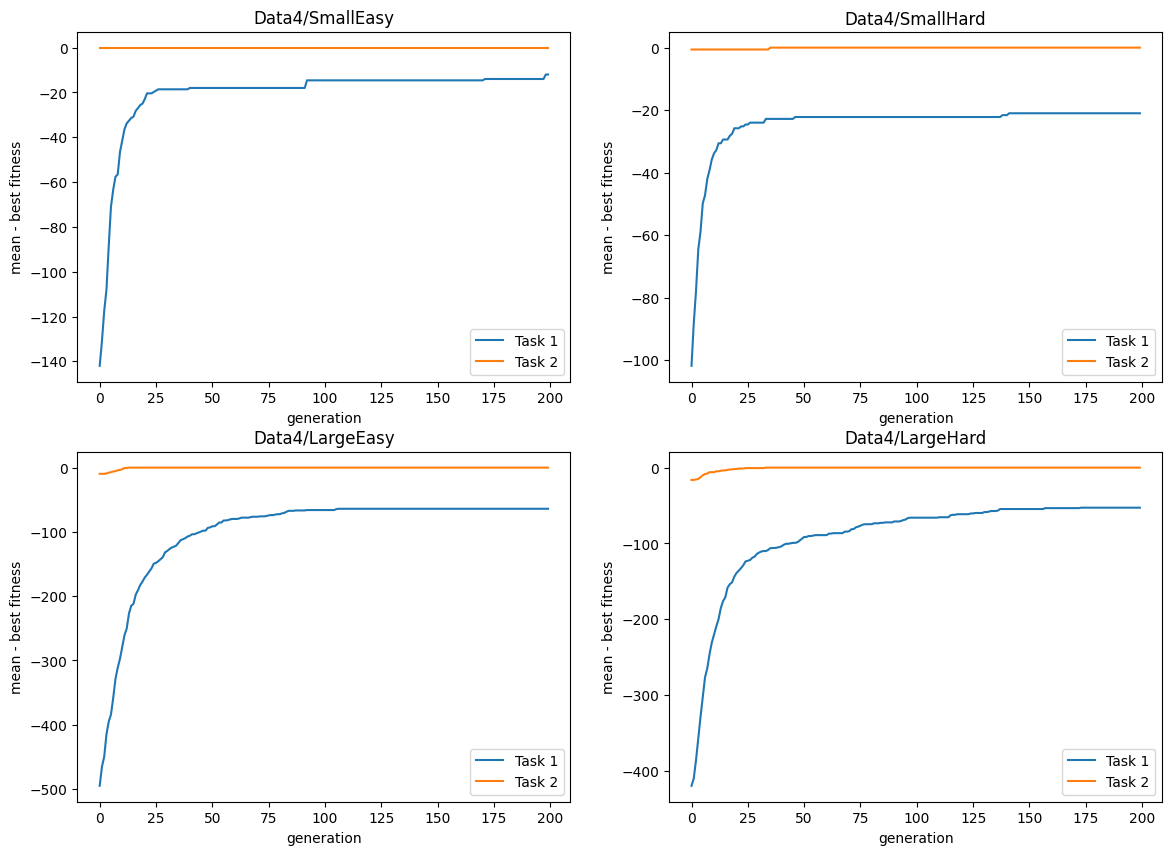

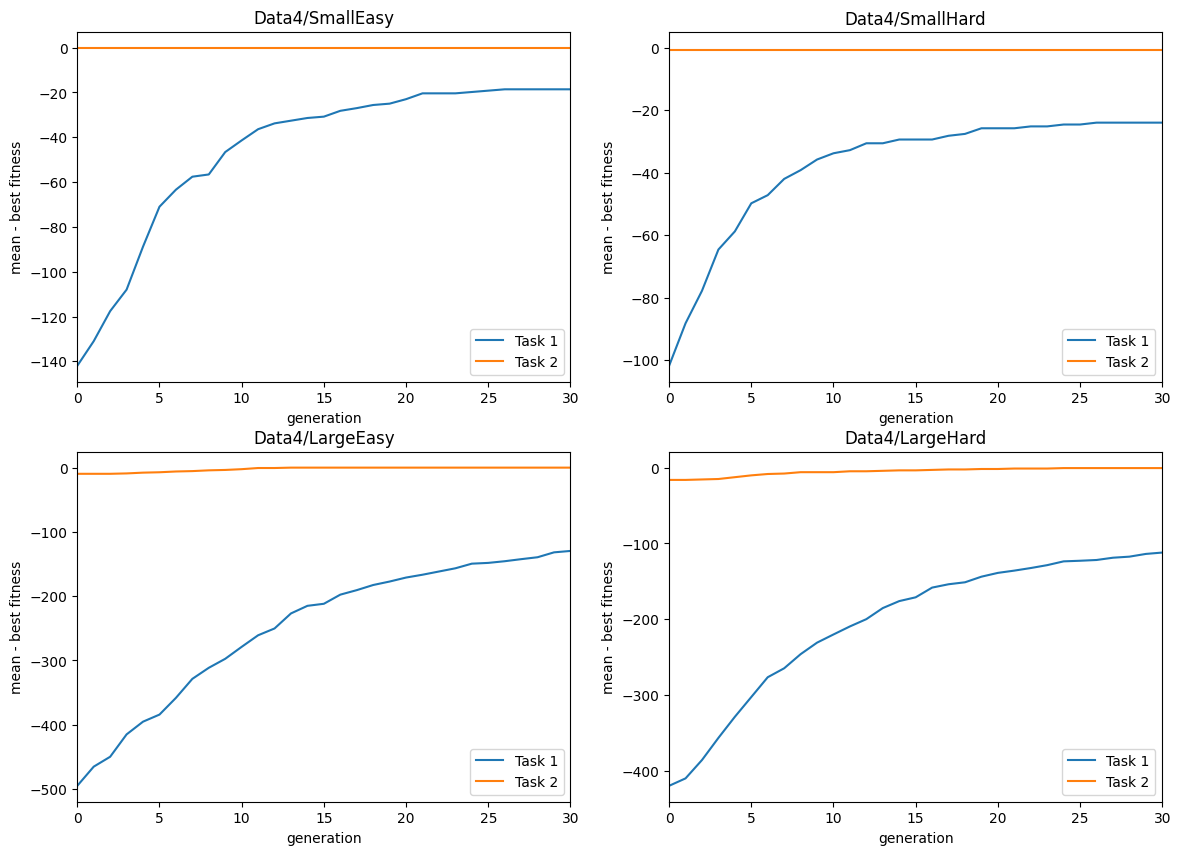

In [ ]:
meanLines12 = grouped12.groupby(["data_set", "method"])["fitnessScores"].apply(lambda c: np.mean(c.tolist(), axis= 0))
METHODS = ["Task 1", "Task 2"]
#Ploting the comparisons graps 4 -> 1 for each dataset

plt.figure(figsize=(14,10))
for i, folder in enumerate(DATA_SETS) : 
    plt.subplot(2, 2, i + 1)
    for method in METHODS :
        plt.plot(meanLines12[folder, method], label = method)
    plt.title(folder)
    plt.xlabel('generation')
    plt.ylabel("mean - best fitness")
    plt.legend()
plt.show()

# Since task2 compared so well compared to the task 1 the comparison on that scale looks completely off
plt.figure(figsize=(14,10))
for i, folder in enumerate(DATA_SETS) : 
    plt.subplot(2, 2, i + 1)
    for method in METHODS :
        plt.plot(meanLines12[folder, method], label = method)
    plt.title(folder)
    plt.xlabel('generation')
    plt.ylabel("mean - best fitness")
    plt.xlim(0, 30)
    plt.legend()
plt.show()



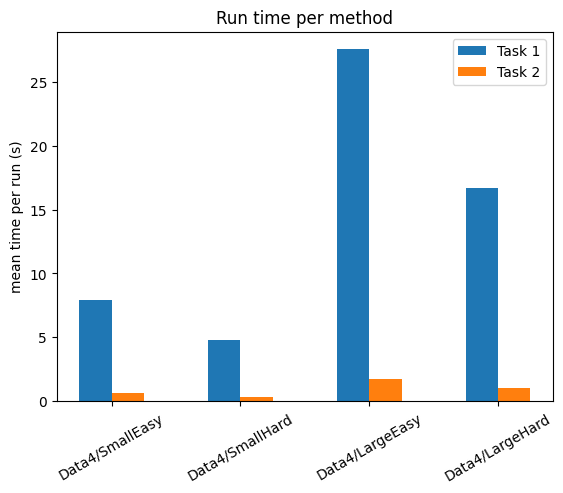

In [ ]:
# Lets compared the times also
x = np.arange(len(DATA_SETS))
width = 0.25
for j, method in enumerate(METHODS):
    times = [compared12.loc[(folder, method), "time_s"] for folder in DATA_SETS]
    plt.bar(x + j * width, times, width, label=method)

plt.xticks(x + width / 2, DATA_SETS, rotation=30)
plt.ylabel("mean time per run (s)")
plt.title("Run time per method")
plt.legend()
plt.show()

## Task 1 vs 2 Evaluation

**1. Fitnes and convergence**

From the summary table and graphs it can be seen that task 2 reaches valid schedule in all 20/20 runs. While task 1 only reached 2 out 5 in smallEasy.

The starting point differs a lot. While task 1 is betweem -100 to -150 on small and -400 to -500 on large, task 2 already start betweem 0 and 15. Which means our initial population did its job with placing every lecture inside opening hours, only once and assigning appropriate teaches. Most big penalties already avoided.

When looking at only task 2 we see, that steps to reach first 0 depend on the dificulty of the data set more than the size. At 90% fullnes almost everything is already filled out and with only 1 teacher per subject its diffult to fix.

Improvements our changes brought:
- Initial population -> improved the fitness with which the populations start
- Crossover -> does not mess up the good start since it only cuts between the lectures which are pressorted by ID, so it can not create any big penalties
- Mutation -> usses small and safe steps -> which lead to small improvements without causing penalties

**2. Time** 

Task 2 performs around 14x faster. The main difference is mutation, same reason as before. Since swap keeps misfiring and retrying. 

The difference betwee the 2 set grows by the size of the dataset and on top of that task 2 always runs the 200 generations even after reaching fitnesss = 0.


## Task 3  : Soft constraints and multi objective fitness

In task 3 we keep the same initial population, crossover and mutation we implemeted in task 2 and also the hard constraints stay the same. We only add the soft constraints, which do not need to be satisfied 100%. Meaning schedule can still be valid even without them.

### 1. Soft constraints - liked hours

They are implemented for teachers preferences about the hours they prefer to teach and in the hours they do not. 

Values: 

- every hour in liked window    -> reward -0.1
- every hour in disliked window -> penalty +0.25

So by our rules it is more important to avoid the disliked hours than to teach in liked ones.

### 2. Soft constraints - same average hours per teacher 

Since everyteacher should teach aproximately the same amount of hours, we compute the average ad then add 0.25 per started hour away from the average:

- ceil|teacher_hours - average| * 0.25

In both the weights of soft constraints are small and the reason for that is so that they do not overpower the stroing constraints.

### 3. Single vs multi objective fitness

1. **Single fitness:** = -(hard + soft) all becomes 1 number. Because of this fitness 0 is no longer means if schedules is valid and we have to check hard penalty separetly.
2. **Multi objective finess:** fitness = [-hard, soft] witj "nsga-2" parent selection

Since nsga-2 is used we need to used a simple trick, because it evaluated each pair of values separetly so [-50, 0.1] would be equaly good as [-6, -0.5]. So to prevent that if the schedule breaks the contraint, we also add the hard penalty to the soft one. So now it will lose in both parameters.


In [ ]:

# FOR MULTI OBJECTIVE OPTIMIZATION
def fSoft(teacherSpots):
    
    # SOFT constraints from task 3
    # • Teacher preferences
    # If one of thoose constarints its right i will lower/increase fitness score!

    teachingHours = []
    issue = 0
    for t in idTeacher:

        name = globalIdTeachersDictionary[t]
        likes = preferences[name]["likes"]
        dislikes = preferences[name]["dislikes"]

        # if spots aren't selected they are 0 so no affect
        # If spots she likes are selected (we subtract that amount)
        # 0.1 so (at 0.25 this influenced other problems like overlaping calasses to occour)
        issue -= 0.10 * np.sum(teacherSpots[t][likes[0]:likes[1]])

        # * 0.25 to lower the importance (at 0.5 tthis influenced other problems like overlaping calasses to occour)
        issue += 0.25 * np.sum(teacherSpots[t][dislikes[0]:dislikes[1]])
    
        # • Teacher balance: everyone teaches (approximately) the same number of hours.
        # Number of hours that a t teacher teachs
        num = np.sum(teacherSpots[t])
        teachingHours.append(num)
    
    avgTeachingHours = np.mean(teachingHours)
    
    for th in teachingHours:
        issue += np.ceil(abs(th - avgTeachingHours)) * 0.25

    return issue

# suitable fitness function that will reward schedules that satisfy the conditions and penalize those that do not.
# (idClass, idClassroom, start, idteacher)
def f_t3(schedule, multiObjectOptimization=False):

    issue = 0
    for cid in idClasses:
        find = 0    
        
        # Find if exists 
        for lecture in schedule:
            if lecture[0] == cid: 
                find += 1
            
        # If one lecture/class is not found penatly is high
        if find == 0: 
            issue += 10

        # If some duplicates
        if find > 1:
            issue += 10

    spots = [ [ 0 for j in range(razred[1]-razred[0])] for razred in classroomTime]
    
    teacherSpots = [ [0 for j in range(24)] for _ in idTeacher]

    for lec in schedule:
                
        id_Class, id_Classroom, startHour, id_Teacher = lec
        id_Class, id_Classroom, startHour, id_Teacher = int(id_Class), int(id_Classroom), int(startHour), int(id_Teacher)
    
        # From slovar of hours i get when does this class end 
        endHour = startHour + slovarTrajanjaUr[id_Class]
        startIndToFill = startHour - classroomTime[id_Classroom][0]
        endIndToFill = endHour - classroomTime[id_Classroom][0]

        # For how many hours the classroom is open
        dolg = classroomTime[id_Classroom][1] - classroomTime[id_Classroom][0]

        if startHour < classroomTime[id_Classroom][0]:       
            issue += abs(classroomTime[id_Classroom][0] - startHour) * 6
                 
        if endHour > classroomTime[id_Classroom][1]:
            issue += (endHour - classroomTime[id_Classroom][1]) * 6
            
        validStart = max(startIndToFill, 0)
        validEnd = min(endIndToFill, dolg)
       
        for i in range(validStart, validEnd):
            spots[id_Classroom][i]+=1

            # Lectures cannot overlap in the same classroom: a single classroom can hold only a single lecture in a given hour.
            # For every value that is more than 1 -> +1 issue
            if spots[id_Classroom][i] > 1: issue += 3 * (spots[id_Classroom][i] - 1)

        # Teachers cannot teach more than one lecture at the same time
        for i in range(startHour, min(endHour, 24)):
            if teacherSpots[id_Teacher][i] > 0:
                issue += 3
            teacherSpots[id_Teacher][i] += 1


        # Every lecture needs to be assigned a teacher (That teaches that class) 
        canTeach = teacherClass[id_Teacher]
        teachingClass = lectureClass[id_Class]

        if teachingClass not in canTeach:
            issue+=10


    # So default approach only one function no multiObjects
    if not multiObjectOptimization:
        issue += fSoft(teacherSpots)
       
    return issue, teacherSpots

def fitness_function_t3(ga_instance, solution, x_idx):
    # solution is flat so I had to make it 2D
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]
    score, _ = f_t3(schedule) 
    return -score


# multi objective optimization -> so multi fitness function 
def multi_fitness_function(ga_instance, solution, x_idx):
    
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]
    scoreHardConst, teacherSpots = f_t3(schedule, multiObjectOptimization=True)
    scoreSoftConts = fSoft(teacherSpots)

    # As in provided link
    # somehow [-53, 0.1] can beat [-6, -0.5], even thought hard constraints are more important so
    # they both beat eachother -53 < -6 and 0.1 > -0.5, so the solution which is closer to zero wins
    
    # invalid schedule -> hard penalty also added to soft, so it loses on both objectives
    if scoreHardConst > 0:
        scoreSoftConts = scoreSoftConts + (scoreHardConst)
    
    return [-scoreHardConst, -scoreSoftConts]

In [ ]:
def run_task3(folder, seed, multi=False, num_generations=200, sol_per_pop=50, num_parents_mating=10):
    global preferences
    set_data(folder)
    preferences = load_preferences(folder)   # fSoft needs the preferences of this data set

    earliest = min(t[0] for t in classroomTime)
    latest   = max(t[1] for t in classroomTime)
    startHours = list(range(earliest, latest))

    gene_space = []
    for _ in range(len(idClasses)):
        gene_space.extend([
            idClasses,
            idClassroom,
            startHours,
            idTeacher])

    # configuring initial population (sol_per_pop)
    random.seed(seed)
    initialPopulation = np.array([initialPopulationFunc() for i in range(sol_per_pop)])

    # 1.-> single fitness
    # 3b -> two objectives + nsga2
    if multi:
        fitness = multi_fitness_function
        parentSelection = "nsga2"
    else:
        fitness = fitness_function_t3
        parentSelection = "sss"              # PyGAD default

    ga_instance = pygad.GA(
        fitness_func=fitness,

        parent_selection_type=parentSelection,
        num_generations=num_generations,
        num_parents_mating=num_parents_mating,
        sol_per_pop=sol_per_pop,
        num_genes=len(gene_space),
        gene_space=gene_space,
        initial_population=initialPopulation,
        crossover_type=crossoverFunction,
        mutation_type=mutation_func,
        random_seed=seed,
        allow_duplicate_genes=True,

        #callbacks
        on_start=on_start,
        on_fitness=on_fitness,
        on_parents=on_parents,
        on_crossover=on_crossover,
        on_mutation=on_mutation,
        on_generation=on_generation)

    # run time
    start = time.perf_counter()
    ga_instance.run()
    totalTime = time.perf_counter() - start

    solution, solution_fitness, solution_idx = ga_instance.best_solution()

    # fitness 0 != valid anymore
    # We need to calculate hard and soft separately for the best schedule
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]

    hard, teacherSpots = f_t3(schedule, multiObjectOptimization=True)
    soft = fSoft(teacherSpots)

    return {
        "hard": hard,
        "soft": soft,
        "time": totalTime,  #total run time of ga
        "times": dict(timeDictionary), #times spit by step
        "solution": solution,
    }

In [ ]:
VERSIONS = ["single", "multi"]

results_t3 = []
for data in DATA_SETS:
    for version in VERSIONS:
        for seed in SEEDS:
            ga_results = run_task3(data, seed, multi=(version == "multi")) # we need true or false
            results_t3.append({
                "data_set": data,
                "version": version,
                "seed": seed,
                "hard": ga_results["hard"],
                "soft": ga_results["soft"],
                "time": ga_results["time"],
            })

results_task3 = pd.DataFrame(results_t3)

summary_task3 = results_task3.groupby(["data_set", "version"]).agg(
    valid=("hard", lambda x: f"{(x == 0).sum()}/{len(x)}"),
    mean_hard=("hard", "mean"),
    best_soft=("soft", "min"),      # lower soft = better
    mean_soft=("soft", "mean"),
    time_s=("time", "mean"),
).round(2)

summary_task3

valid  mean_hard  best_soft  mean_soft  time_s
data_set        version                                               
Data4/LargeEasy multi     5/5        0.0       0.75       1.90   20.63
                single    5/5        0.0       1.20       1.76    5.33
Data4/LargeHard multi     3/5        1.2       1.10       1.62   16.38
                single    2/5        1.8       0.95       1.57    2.27
Data4/SmallEasy multi     5/5        0.0       0.35       0.73   14.28
                single    5/5        0.0       0.05       0.57    1.77
Data4/SmallHard multi     4/5        0.6       0.35       0.50   14.22
                single    4/5        0.6       0.35       0.60    0.81

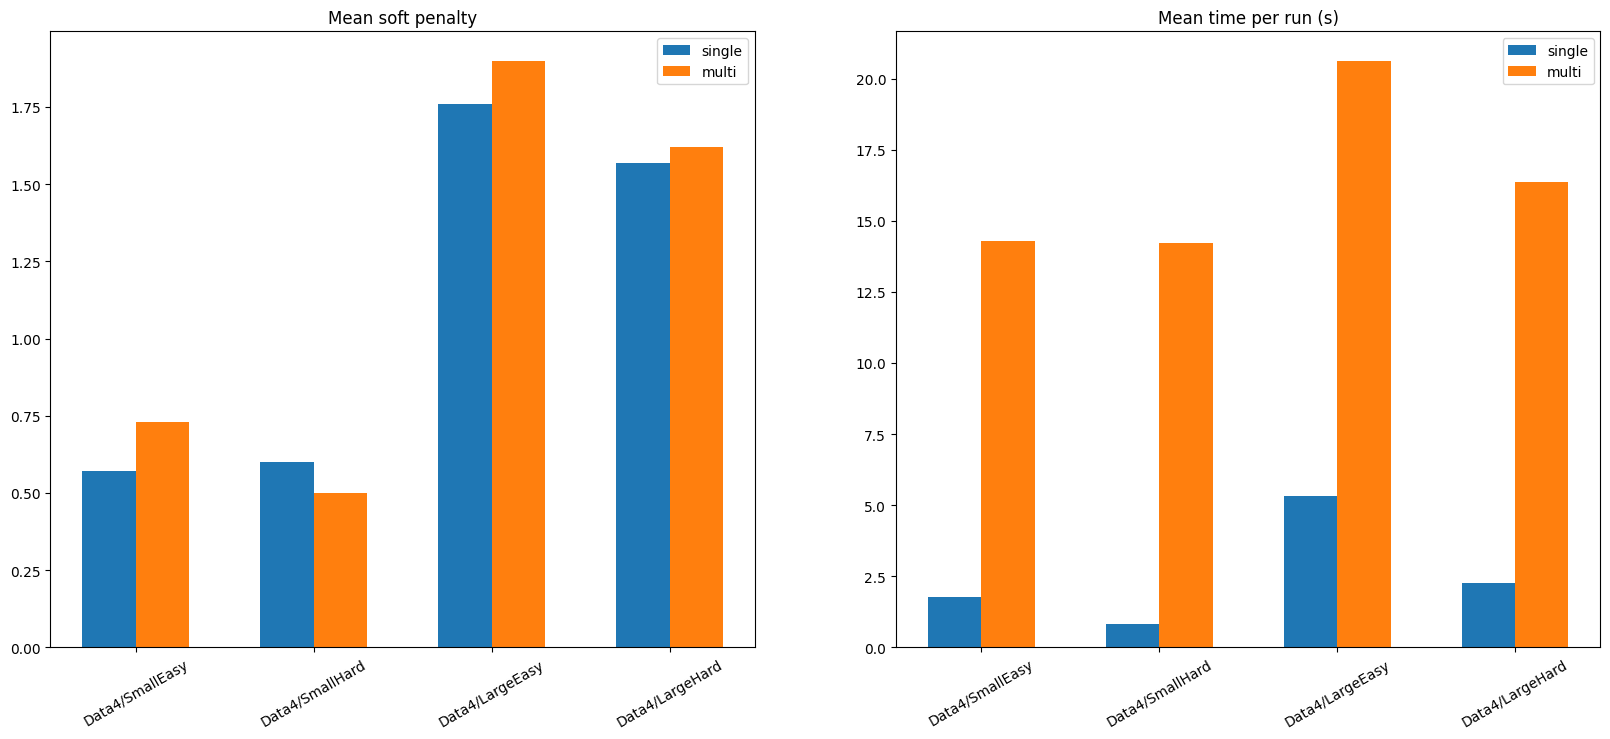

In [ ]:
x = np.arange(len(DATA_SETS))
width = 0.3
names_titles = [("mean_soft", "Mean soft penalty"), ("time_s", "Mean time per run (s)")]

plt.figure(figsize=(20, 8))
for k, (column, title) in enumerate(names_titles):
    plt.subplot(1, 2, k + 1)
    for j, version in enumerate(VERSIONS):
        values = [summary_task3.loc[(folder, version), column] for folder in DATA_SETS]
        plt.bar(x + j * width, values, width, label=version)
    plt.xticks(x + width / 2, DATA_SETS, rotation=30)
    plt.title(title)
    plt.legend()
plt.show()

## Task 3 evaluation : single vs multi-objective

1. **Validity of data**

- From the summaray table for task 3 it can be seen that booth reach valid in all runs on the easy sets. For the hard sets some runs fail, hard to say which is better since we are performing on random seed and the difference for 10 runs for both is 1 failed run
- If we compare it to the Task 2 which on the same data performed 20/20, we can conclude that adding soft constraints made it much harder to solve. Also we must not forget that at hard rooms are 90% full which means, adding prefered teaching times makes it exstremely hard.


2. **Soft constraints**


- We plotted the mean soft penatly for single and multi optimization. It is hard to say that 1 outperformed the other since results are relatively close. But single was lower on 3/4 data sets. The best multi soft scores were scored on the large easy data 1.2 for multi and 0.75 for single, which is interesting considering it lost overall.
- The differences are <0.3 which is around 1-3 hours of preferences. But here we have to consider the little trick we usd for multi, since it cause correlated behavior, meaning our multi first works as hard constrains and after its done only then it works on soft constraints. So very similar to single fitness.

3. **Time**

- Multi is much slower than single, but almost the same in between the data sets. The reason for that is probably the "nsga-2" doing the sorting in every generation which is also dependant on the population size.The time for single scales with data size very similar to Task 2.

So in conlusion with our set weights and the trick for multi, we see multi gives pretty similar results to single fitness, even slitly worse. Meaning single fitness is the better choice for this task.
